# Chapter 3: Classical RL Algorithms — Case Study

## MC vs TD Prediction and Q-Learning vs SARSA on the Windy Desert

This notebook demonstrates tabular RL algorithms from Chapter 3 using the
`rlbook` package. We compare Monte Carlo vs TD(0) value prediction, then
Q-Learning vs SARSA for control on the stochastic Windy Desert environment.


In [1]:
# Setup — run once
# Local:  pip install -e .
# Colab:  !pip install -q "git+https://github.com/rl-textbook/reinforcement-learning.git"

import math
import random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Reproducibility
SEED = 2
random.seed(SEED)
np.random.seed(SEED)
print(f"Seed: {SEED}")

from rlbook.environments import create_windy_desert_env, apply_reward_shaping
from rlbook.algorithms.dynamic_programming import value_iteration, extract_policy
from rlbook.algorithms.tabular import (
    make_epsilon_greedy_policy, first_visit_mc_prediction, td0_prediction,
    q_learning, sarsa, extract_greedy_policy, evaluate_policy,
)
from rlbook.core import rmse, VisitationCounter, mc_td_traces, run_value_evolution
from rlbook.viz import (
    visualize_grid_world_desert, plot_policy_evolution,
    visualize_policy_path, plot_visitation_mc_vs_td,
    plot_value_snapshots, animate_value_evolution,
)


Seed: 2


## Part 1: The Windy Desert Environment

A 6×8 stochastic grid where the agent must navigate from Start to the Oasis
while avoiding quicksand traps. Wind causes drift: the agent moves in the
intended direction with probability p=0.70, and drifts to each perpendicular
direction with probability p=0.15.


Grid: 6×8, States: 48


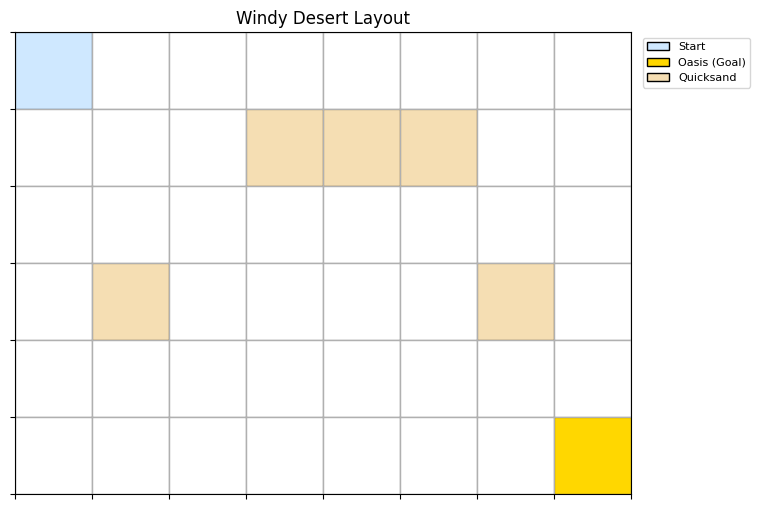

In [2]:
env = create_windy_desert_env()  # p_intended=0.70, p_perp=0.15
print(f"Grid: {env.grid_height}×{env.grid_width}, States: {len(env.states)}")

visualize_grid_world_desert(env=env, title="Windy Desert Layout")
plt.show()


## Part 2: MC vs TD(0) Value Prediction

We compute the optimal value function \(V^*\) via Value Iteration, then compare
how First-Visit MC and TD(0) estimate it from sampled experience under the
greedy policy.


In [3]:
# Compute V* and a greedy policy
V_star = value_iteration(env)
greedy_pi = extract_policy(env, V_star)

# Convert to stochastic format (epsilon=0 = pure greedy)
epsilon = 0.0
eps_policy = make_epsilon_greedy_policy(greedy_pi, env.actions, epsilon=epsilon)


Value iteration converged after 64 iterations


In [4]:
# Run MC and TD(0) for 5000 episodes with periodic snapshots
total_episodes = 5000
snap_every = 100
mc_snapshots, td_snapshots = mc_td_traces(
    eps_policy,
    env,
    total_episodes=total_episodes,
    snapshot_every=snap_every,
    alpha_td=0.1,
    gamma=1.0,
)


### Value Estimates After Training

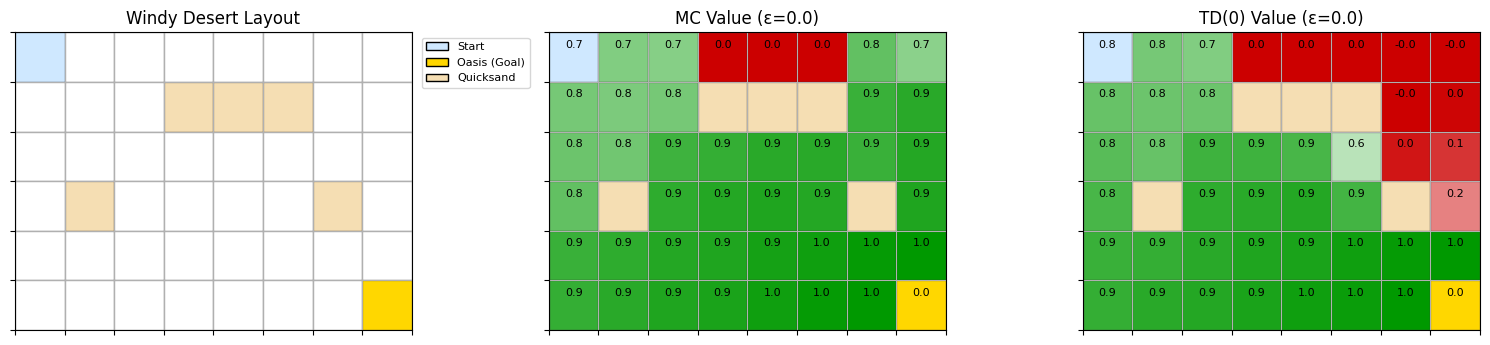

In [5]:
V_mc_final = mc_snapshots[-1]
V_td_final = td_snapshots[-1]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
visualize_grid_world_desert(env=env, ax=axes[0], title="Windy Desert Layout", show_legend=True)
visualize_grid_world_desert(values=V_mc_final, env=env, ax=axes[1], title=f"MC Value (ε={epsilon})", show_legend=False)
visualize_grid_world_desert(values=V_td_final, env=env, ax=axes[2], title=f"TD(0) Value (ε={epsilon})", show_legend=False)
plt.tight_layout()
plt.show()


### RMSE Convergence: MC vs TD(0)

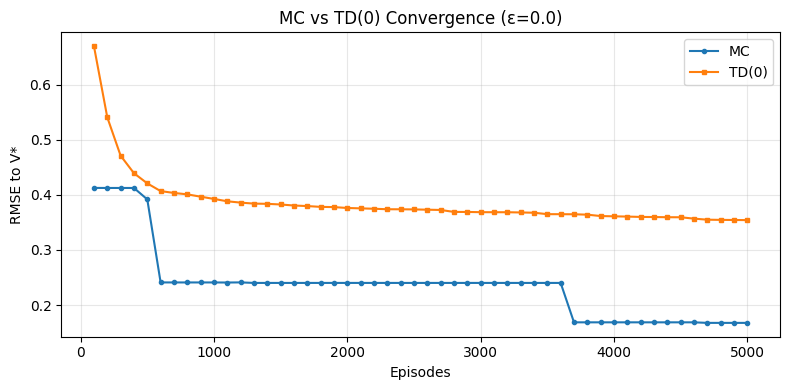

In [6]:
iters = list(range(snap_every, total_episodes + 1, snap_every))
mc_err = [rmse(V, V_star) for V in mc_snapshots]
td_err = [rmse(V, V_star) for V in td_snapshots]

plt.figure(figsize=(8, 4))
plt.plot(iters, mc_err, 'o-', label='MC', markersize=3)
plt.plot(iters, td_err, 's-', label='TD(0)', markersize=3)
plt.xlabel('Episodes')
plt.ylabel('RMSE to V*')
plt.title(f'MC vs TD(0) Convergence (ε={epsilon})')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Visitation Patterns

MC and TD(0) visit states differently. MC must wait for episode completion,
while TD(0) updates online after each step.


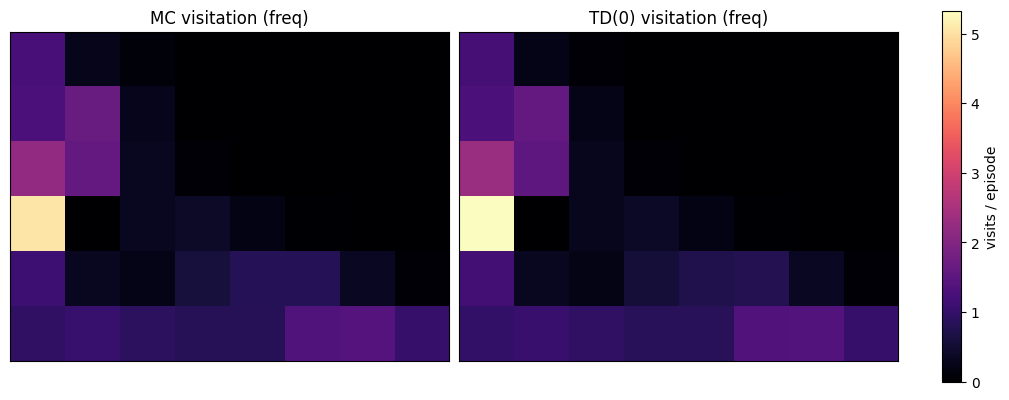

In [7]:
mc_visit = VisitationCounter(len(env.states))
td_visit = VisitationCounter(len(env.states))

_ = first_visit_mc_prediction(
    eps_policy,
    env,
    num_episodes=2000,
    gamma=1.0,
    visit=mc_visit,
)
_ = td0_prediction(
    eps_policy,
    env,
    num_episodes=2000,
    gamma=1.0,
    visit=td_visit,
)

plot_visitation_mc_vs_td(mc_visit, td_visit, env, mode="freq")


### Value Function Evolution

Watch how MC and TD(0) estimates of \(V\) evolve over training episodes.


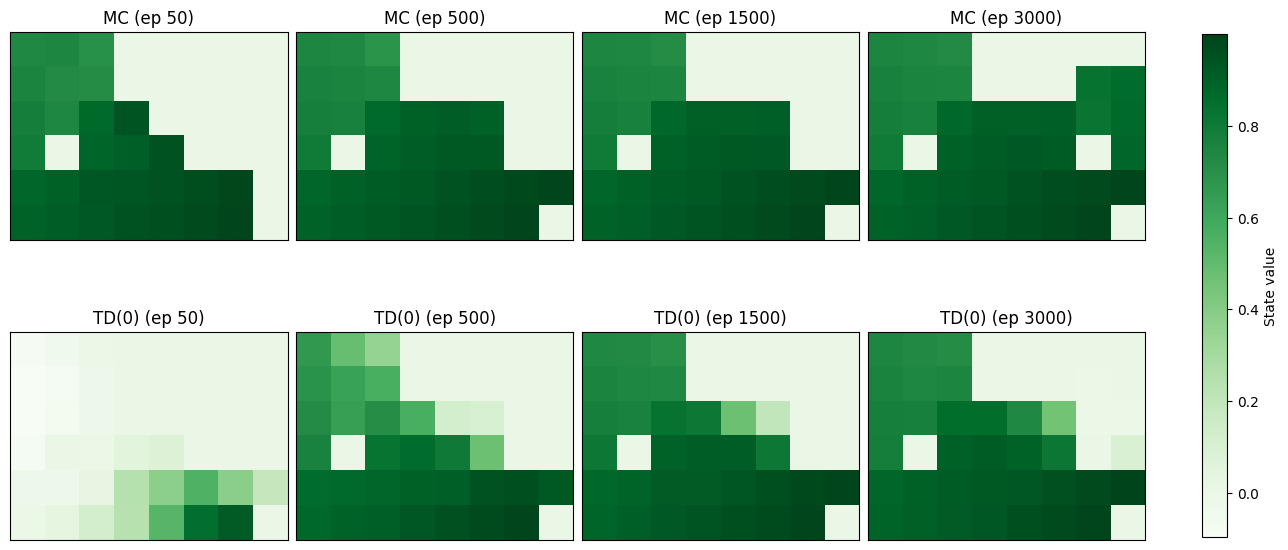

In [8]:
rec_mc, rec_td = run_value_evolution(
    env,
    eps_policy,
    total_episodes=3000,
    snapshot_every=50,
    gamma=1.0,
    alpha_td=0.1,
)

# Static snapshots at key checkpoints
plot_value_snapshots(rec_mc, rec_td, checkpoints=[50, 500, 1500, 3000])


In [9]:
# Animated evolution (renders inline in Jupyter/Colab)
anim = animate_value_evolution(rec_mc, rec_td, interval_ms=40)
HTML(anim.to_jshtml())


## Part 3: Q-Learning vs SARSA Control

Now we switch to a shaped-reward environment with reduced stochasticity
(p=0.90) and compare Q-Learning (off-policy) vs SARSA (on-policy) for
learning control policies from scratch.


In [10]:
env = create_windy_desert_env(p_intended=0.90, p_perp=0.05)
apply_reward_shaping(env, step_cost=-1.0, hole_penalty=-100.0, goal_reward=+10.0)


In [11]:
# Train Q-Learning and SARSA under matched settings
episodes = 10000
alpha = 0.1
gamma = 1.0
epsilon = 0.1
snapshots = (50, 200, 500, 10000)

Q_q, snaps_q = q_learning(
    env,
    episodes=episodes,
    alpha=alpha,
    gamma=gamma,
    epsilon=epsilon,
    snapshots=snapshots,
    max_steps=400,
)
Q_s, snaps_s = sarsa(
    env,
    episodes=episodes,
    alpha=alpha,
    gamma=gamma,
    epsilon=epsilon,
    snapshots=snapshots,
    max_steps=400,
)


### Policy Evolution During Training

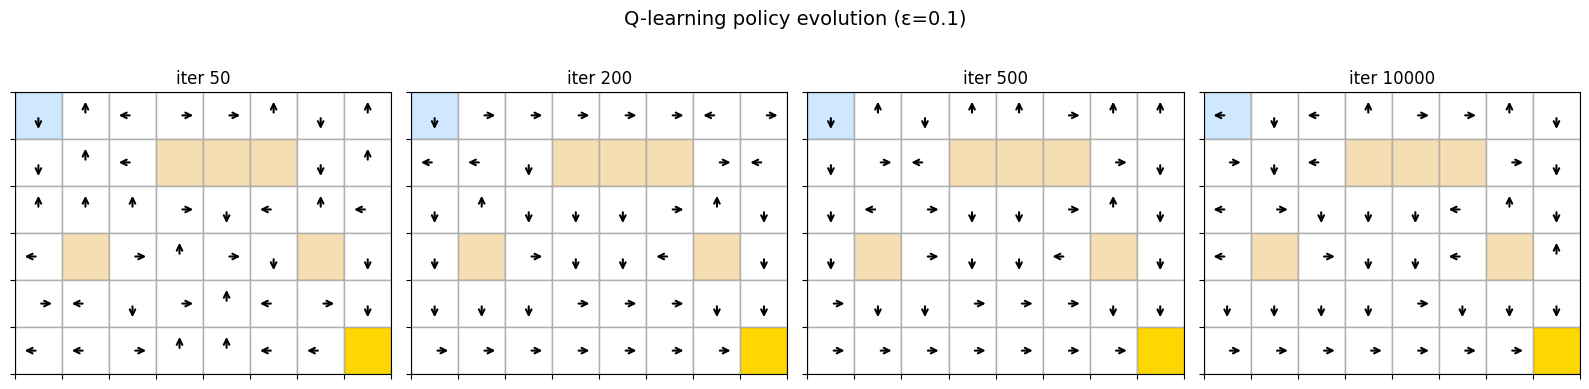

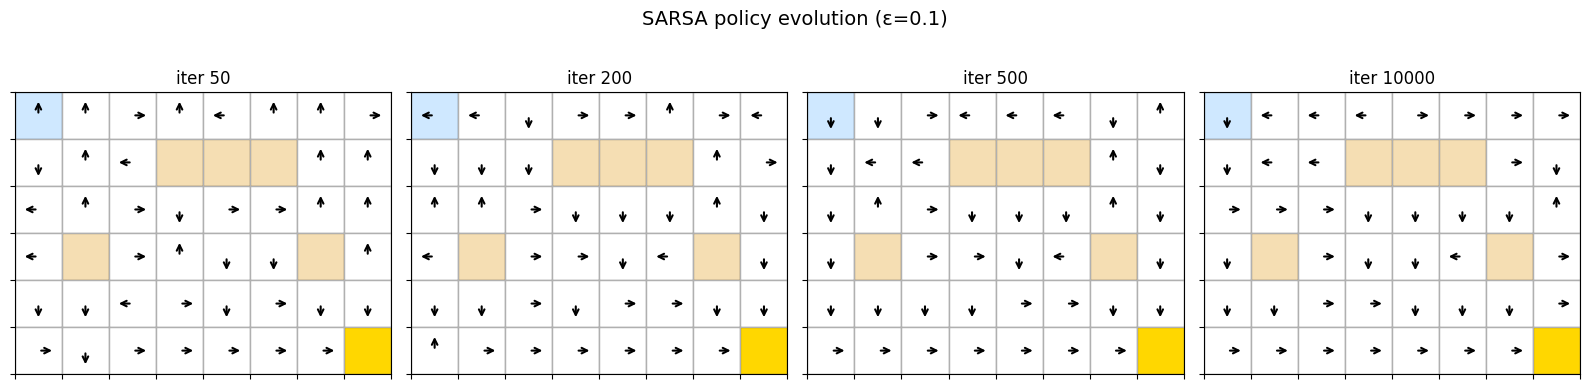

In [12]:
plot_policy_evolution(env, snaps_q, title='Q-learning policy evolution (ε=0.1)')
plot_policy_evolution(env, snaps_s, title='SARSA policy evolution (ε=0.1)')


### Final Learned Paths

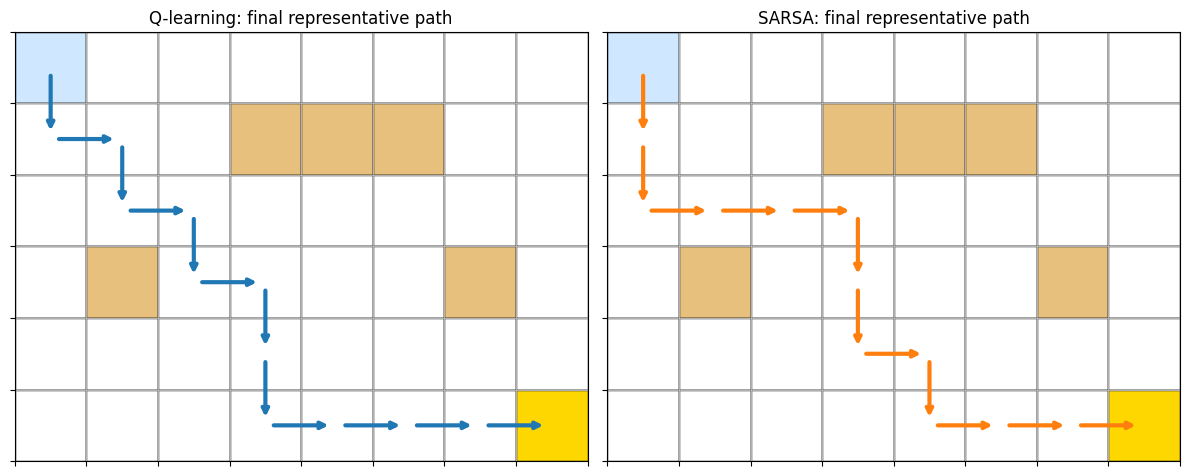

In [13]:
pi_q = extract_greedy_policy(Q_q, env)
pi_s = extract_greedy_policy(Q_s, env)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
visualize_policy_path(env, pi_q, color='C0', ax=axes[0], title='Q-learning: final representative path')
visualize_policy_path(env, pi_s, color='C1', ax=axes[1], title='SARSA: final representative path')
plt.tight_layout()
plt.show()


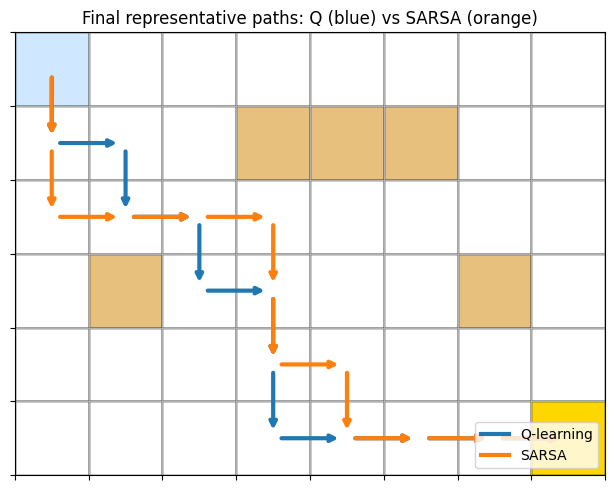

In [14]:
# Combined overlay: both representative paths on one map
fig, ax = plt.subplots(1, 1, figsize=(7, 5))
visualize_policy_path(
    env,
    pi_q,
    color='C0',
    ax=ax,
    title='Final representative paths: Q (blue) vs SARSA (orange)',
)
visualize_policy_path(env, pi_s, color='C1', ax=ax)

legend_lines = [
    Line2D([0], [0], color='C0', lw=3, label='Q-learning'),
    Line2D([0], [0], color='C1', lw=3, label='SARSA'),
]
ax.legend(handles=legend_lines, loc='lower right')
plt.tight_layout()
plt.show()


### Quantitative Evaluation

In [15]:
ret_ql, steps_ql, success_ql = evaluate_policy(env, pi_q, episodes=100)
ret_sa, steps_sa, success_sa = evaluate_policy(env, pi_s, episodes=100)

print(f"Q-Learning (10k eps): return={ret_ql:.2f}, steps={steps_ql:.1f}, success={success_ql:.0f}%")
print(f"SARSA      (10k eps): return={ret_sa:.2f}, steps={steps_sa:.1f}, success={success_sa:.0f}%")


Q-Learning (10k eps): return=-30.76, steps=33.0, success=92%
SARSA      (10k eps): return=-5.96, steps=13.7, success=97%


## Key Takeaways

MC converges more reliably to \(V^*\) under a fixed policy but requires complete
episodes. TD(0) updates online and can learn faster in practice with a good
learning rate. For control, Q-Learning's off-policy updates drive it toward the
greedy solution under the shaped objective, while SARSA's on-policy updates can
remain more conservative in stochastic environments.

In the final control plots, the displayed paths are **representative** paths:
self-loop wall bumps are compressed so the learned policy is easier to inspect on
the stochastic grid.
